# 07 · Feedforward Neural Networks and Backpropagation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anuxlab/deep-learning-systems/blob/main/notebooks/07-mlp-backprop/07_mlp_backprop.ipynb)
[![Run on GitHub Actions](https://img.shields.io/badge/run-GitHub%20Actions-2088FF?logo=githubactions&logoColor=white)](https://github.com/anuxlab/deep-learning-systems/actions/workflows/nb-07-mlp-backprop.yml)

| | |
|---|---|
| **Wiki chapter** | [Module 07](https://github.com/anuxlab/deep-learning-systems/wiki/Module-07) |
| **Level** | Intermediate |
| **Typical CPU runtime** | ~1 min (GitHub free runner, no GPU) |
| **Prerequisites** | Modules 02, 05, 06 |

## What you will do

- Write forward and backward passes of an MLP in NumPy (batch matrix form).
- Verify every gradient with finite differences (the gradient check).
- Train on XOR, a regression task and a classification task; plot decision boundaries.
- Re-implement in PyTorch and show the two implementations produce identical gradients.
- Use the *tiny-batch overfit* sanity test.

> **How to use this notebook.** Read each markdown cell, *predict* what the next code cell will print, then run it.
> Every section ends with `check(...)` assertions: if one fails, something in your understanding (or the code) is off.
> Figures are saved to `figures/` and a machine-readable summary to `metrics.json` next to this notebook.

## 0 · Setup and reproducibility

We import shared helpers (`show` saves each figure to `figures/`, `check` asserts and logs, `timer` logs wall-clock time), fix all random seeds and print an environment report so every run is traceable (see the wiki's *Implementation and Research Standards*).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "_common"))   # shared helpers: notebooks/_common/dlsys.py
from dlsys import *                                       # np, plt, torch, seed_everything, show, check, timer, ...

SEED = seed_everything(42)
ENV = env_report()

16:14:08 | INFO | seed set to 42


          python: 3.12.16
        platform: Linux-7.0.0-1019-azure-x86_64-with-glibc2.43
       cpu_count: 4
          ram_gb: 15.6
           numpy: 2.5.5
           scipy: 1.18.1
         sklearn: 1.9.1
      matplotlib: 3.11.2
           torch: 2.15.0+cpu
  cuda_available: False
  github_actions: True
          run_id: 43905072217
          commit: b01a9783769e1190f41f107db215f8300e78b79c


## 1 · Forward propagation in matrix form
For a batch $X\in\mathbb R^{B\times d}$ and layers $l=1..L$:
$$Z^{(l)}=A^{(l-1)}W^{(l)}+b^{(l)},\qquad A^{(l)}=\phi(Z^{(l)}),\qquad A^{(0)}=X.$$
Shapes: $W^{(l)}\in\mathbb R^{n_{l-1}\times n_l}$, $b^{(l)}\in\mathbb R^{n_l}$ (broadcast over the batch). We cache every $Z$ and $A$ because the backward pass needs them.

## 2 · Backpropagation — the four equations
With loss $\mathcal L$ and error signal $\delta^{(l)}=\partial\mathcal L/\partial Z^{(l)}$:

1. Output: $\delta^{(L)}=\partial\mathcal L/\partial A^{(L)}\odot\phi'(Z^{(L)})$ — for softmax+CE or sigmoid+BCE or linear+MSE this is simply $(\hat y-y)/B$.
2. Propagate: $\delta^{(l)}=\big(\delta^{(l+1)}W^{(l+1)\top}\big)\odot\phi'(Z^{(l)})$.
3. Weights: $\partial\mathcal L/\partial W^{(l)}=A^{(l-1)\top}\delta^{(l)}$.
4. Biases: $\partial\mathcal L/\partial b^{(l)}=\sum_{\text{batch}}\delta^{(l)}$.

Below is a complete NumPy MLP supporting `tanh`/`relu`/`sigmoid` hidden units and three output heads.

In [2]:
class MLP:
    def __init__(self, sizes, act="tanh", out="softmax", seed=0):
        r = np.random.default_rng(seed); self.act, self.out = act, out
        # He/Xavier-style scaling keeps activations O(1) (see Module 09)
        self.W = [r.normal(0, np.sqrt((2.0 if act == "relu" else 1.0) / m), size=(m, n)) for m, n in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(n) for n in sizes[1:]]
    def _phi(self, z):
        return np.tanh(z) if self.act == "tanh" else np.maximum(0, z) if self.act == "relu" else 1 / (1 + np.exp(-z))
    def _dphi(self, z, a):
        return 1 - a ** 2 if self.act == "tanh" else (z > 0).astype(float) if self.act == "relu" else a * (1 - a)
    def forward(self, X):
        self.Z, self.A = [], [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = self.A[-1] @ W + b; self.Z.append(z)
            if l < len(self.W) - 1: self.A.append(self._phi(z))
            else:
                if self.out == "softmax": e = np.exp(z - z.max(1, keepdims=True)); a = e / e.sum(1, keepdims=True)
                elif self.out == "sigmoid": a = 1 / (1 + np.exp(-z))
                else: a = z
                self.A.append(a)
        return self.A[-1]
    def loss(self, X, Y):
        P = self.forward(X)
        if self.out == "softmax": return -np.mean(np.sum(Y * np.log(P + 1e-12), 1))
        if self.out == "sigmoid": return -np.mean(Y * np.log(P + 1e-12) + (1 - Y) * np.log(1 - P + 1e-12))
        return 0.5 * np.mean(np.sum((P - Y) ** 2, 1))
    def backward(self, Y):
        B = Y.shape[0]; gW, gb = [None] * len(self.W), [None] * len(self.W)
        delta = (self.A[-1] - Y) / B                       # eq. 1 (all three heads share this form)
        if self.out == "sigmoid": delta = delta / Y.shape[1]  # BCE averaged over outputs too
        for l in reversed(range(len(self.W))):
            gW[l] = self.A[l].T @ delta; gb[l] = delta.sum(0)             # eqs. 3, 4
            if l > 0: delta = (delta @ self.W[l].T) * self._dphi(self.Z[l - 1], self.A[l])   # eq. 2
        return gW, gb
    def step(self, gW, gb, lr):
        for l in range(len(self.W)): self.W[l] -= lr * gW[l]; self.b[l] -= lr * gb[l]
    def predict(self, X): return self.forward(X)
print("MLP class defined")

MLP class defined


## 3 · The gradient check
For every parameter $\theta$: compare $\partial\mathcal L/\partial\theta$ from backprop with $\frac{\mathcal L(\theta+h)-\mathcal L(\theta-h)}{2h}$. We report the **relative error** $\frac{\|g_a-g_n\|}{\|g_a\|+\|g_n\|}$ — below $10^{-6}$ is excellent. We test all activation × head combinations. (Rule from the wiki: *always gradient-check new layers.*)

In [3]:
def grad_check(net, X, Y, h=1e-6):
    net.loss(X, Y); gW, gb = net.backward(Y); worst = 0
    for params, grads in [(net.W, gW), (net.b, gb)]:
        for P, G in zip(params, grads):
            num = np.zeros_like(P)
            for idx in np.ndindex(*P.shape):
                old = P[idx]; P[idx] = old + h; lp = net.loss(X, Y); P[idx] = old - h; lm = net.loss(X, Y); P[idx] = old
                num[idx] = (lp - lm) / (2 * h)
            worst = max(worst, np.linalg.norm(G - num) / (np.linalg.norm(G) + np.linalg.norm(num) + 1e-12))
    return worst
r = np.random.default_rng(0); Xg = r.normal(size=(6, 4))
for act in ["tanh", "relu", "sigmoid"]:
    for out, Yg in [("softmax", np.eye(3)[r.integers(0, 3, 6)]), ("sigmoid", r.integers(0, 2, (6, 3)).astype(float)), ("linear", r.normal(size=(6, 3)))]:
        net = MLP([4, 5, 5, 3], act=act, out=out, seed=1); err = grad_check(net, Xg, Yg)
        check(err < 1e-5, f"hidden={act:8s} head={out:8s} relative gradient error = {err:.2e}")

  ✅ hidden=tanh     head=softmax  relative gradient error = 8.10e-10
  ✅ hidden=tanh     head=sigmoid  relative gradient error = 1.95e-09
  ✅ hidden=tanh     head=linear   relative gradient error = 6.27e-10
  ✅ hidden=relu     head=softmax  relative gradient error = 7.40e-10
  ✅ hidden=relu     head=sigmoid  relative gradient error = 6.29e-10
  ✅ hidden=relu     head=linear   relative gradient error = 5.23e-10
  ✅ hidden=sigmoid  head=softmax  relative gradient error = 1.20e-08
  ✅ hidden=sigmoid  head=sigmoid  relative gradient error = 1.28e-08
  ✅ hidden=sigmoid  head=linear   relative gradient error = 7.92e-09


## 4 · XOR: a hidden layer makes the impossible easy
Module 04 showed a single neuron cannot compute XOR. A 2-4-1 MLP trained with backprop learns it. We plot the loss and the learned decision surface.

XOR predictions: [0.    0.999 0.999 0.001]  loss: 0.00077
  ✅ MLP solves XOR


16:14:10 | INFO | figure saved -> figures/xor_mlp.png


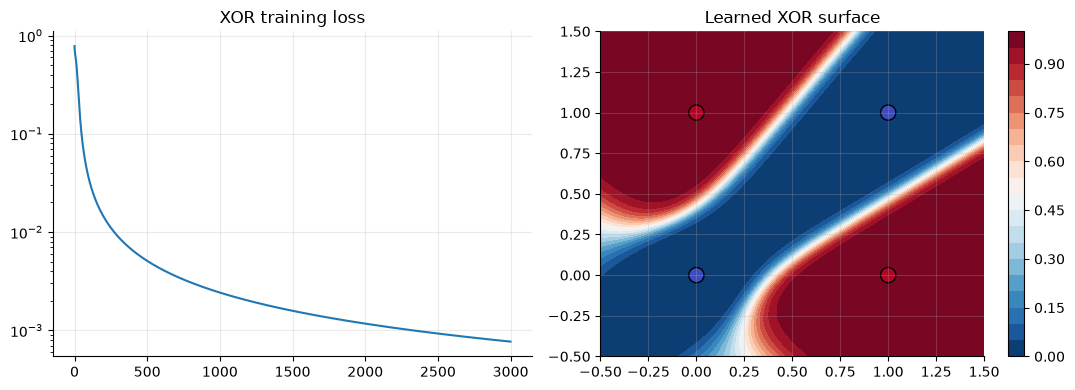

In [4]:
Xx = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float); Yx = np.array([[0], [1], [1], [0]], float)
net = MLP([2, 4, 1], act="tanh", out="sigmoid", seed=3); losses = []
for ep in range(3000):
    net.loss(Xx, Yx); gW, gb = net.backward(Yx); net.step(gW, gb, 1.0); losses.append(net.loss(Xx, Yx))
pred = net.predict(Xx).ravel(); print("XOR predictions:", np.round(pred, 3), " loss:", round(losses[-1], 5))
check(np.all((pred > .5) == (Yx.ravel() > .5)), "MLP solves XOR")
g = np.linspace(-.5, 1.5, 200); gx, gy = np.meshgrid(g, g); surf = net.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); ax[0].semilogy(losses); ax[0].set_title("XOR training loss")
c = ax[1].contourf(gx, gy, surf, 20, cmap="RdBu_r"); ax[1].scatter(*Xx.T, c=Yx.ravel(), cmap="coolwarm", edgecolor="k", s=120); ax[1].set_title("Learned XOR surface"); fig.colorbar(c, ax=ax[1])
show("xor_mlp")

## 5 · Classification (two moons) and regression (noisy sine)
Softmax head with cross-entropy for classification; linear head with MSE for regression. We use mini-batch SGD with momentum-free updates and report held-out accuracy / error.

two moons test accuracy: 0.9555555555555556
  ✅ two-moons accuracy > 93%
16:14:10 | INFO | figure saved -> figures/moons_numpy.png


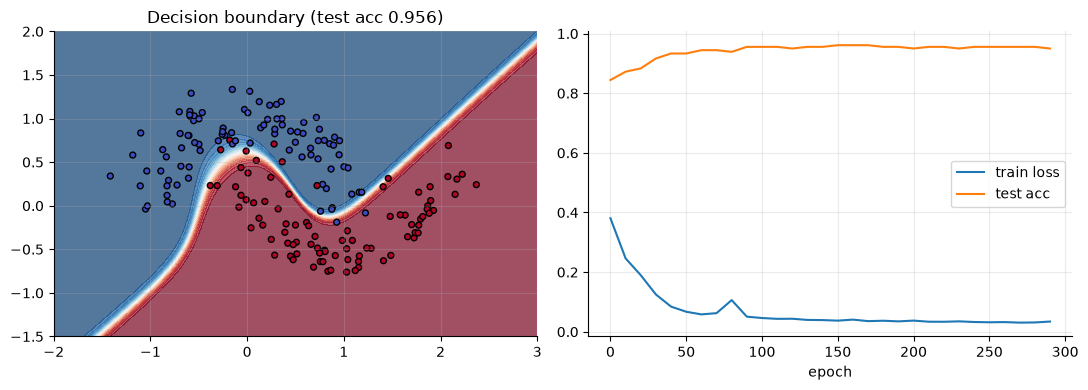

regression MSE vs the true sine: 0.00933
  ✅ regression recovers the underlying sine (MSE well below the signal variance 0.5)
16:14:11 | INFO | figure saved -> figures/regression_numpy.png


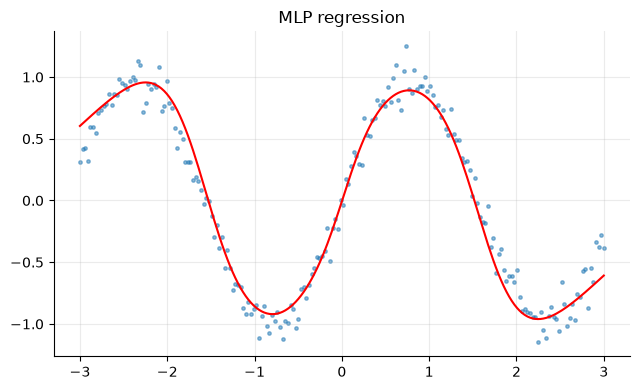

In [5]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
Xm, ym = make_moons(600, noise=.2, random_state=0); Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=.3, random_state=0)
Ytr = np.eye(2)[ytr]
net = MLP([2, 16, 16, 2], act="tanh", out="softmax", seed=0); hist = []
for ep in range(300):
    idx = np.random.default_rng(ep).permutation(len(Xtr))
    for s in range(0, len(idx), 32):
        b_ = idx[s:s + 32]; net.loss(Xtr[b_], Ytr[b_]); gW, gb = net.backward(Ytr[b_]); net.step(gW, gb, .1)
    if ep % 10 == 0: hist.append((ep, net.loss(Xtr, Ytr), (net.predict(Xte).argmax(1) == yte).mean()))
acc = (net.predict(Xte).argmax(1) == yte).mean(); print("two moons test accuracy:", acc)
check(acc > .93, "two-moons accuracy > 93%"); METRICS["moons_test_acc_numpy"] = acc
g = np.linspace(-2, 3, 200); gx, gy = np.meshgrid(g, np.linspace(-1.5, 2, 200))
pp = net.predict(np.c_[gx.ravel(), gy.ravel()])[:, 1].reshape(gx.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); ax[0].contourf(gx, gy, pp, 20, cmap="RdBu_r", alpha=.7); ax[0].scatter(*Xte.T, c=yte, cmap="coolwarm", edgecolor="k", s=18); ax[0].set_title(f"Decision boundary (test acc {acc:.3f})")
h = np.array(hist); ax[1].plot(h[:, 0], h[:, 1], label="train loss"); ax[1].plot(h[:, 0], h[:, 2], label="test acc"); ax[1].legend(); ax[1].set_xlabel("epoch")
show("moons_numpy")

xr = np.linspace(-3, 3, 200)[:, None]; yr = np.sin(2 * xr) + .1 * np.random.default_rng(1).normal(size=xr.shape)
reg = MLP([1, 32, 32, 1], act="tanh", out="linear", seed=1)
for ep in range(8000):
    reg.loss(xr, yr); gW, gb = reg.backward(yr); reg.step(gW, gb, .1)
mse = np.mean((reg.predict(xr) - np.sin(2 * xr)) ** 2); print("regression MSE vs the true sine:", round(mse, 5))
check(mse < .02, "regression recovers the underlying sine (MSE well below the signal variance 0.5)")
plt.scatter(xr, yr, s=6, alpha=.5); plt.plot(xr, reg.predict(xr), "r"); plt.title("MLP regression"); show("regression_numpy")

## 6 · The PyTorch version and a cross-check
PyTorch's autograd computes the same gradients by recording the graph. To compare *exactly*, we copy our NumPy weights into an `nn.Sequential` (float64) and compare every gradient. Differences should be ~1e-16.

In [6]:
net_np = MLP([4, 6, 3], act="tanh", out="softmax", seed=5)
r = np.random.default_rng(9); Xb = r.normal(size=(8, 4)); yb = r.integers(0, 3, 8); Yb = np.eye(3)[yb]
net_np.loss(Xb, Yb); gW, gb = net_np.backward(Yb)
tm = nn.Sequential(nn.Linear(4, 6), nn.Tanh(), nn.Linear(6, 3)).double()
with torch.no_grad():
    for lin, W, b in zip([tm[0], tm[2]], net_np.W, net_np.b): lin.weight.copy_(torch.tensor(W.T)); lin.bias.copy_(torch.tensor(b))
loss_t = F.cross_entropy(tm(torch.tensor(Xb)), torch.tensor(yb)); loss_t.backward()
check(np.isclose(loss_t.item(), net_np.loss(Xb, Yb)), "forward losses agree")
for i, lin in enumerate([tm[0], tm[2]]):
    check(np.allclose(lin.weight.grad.numpy().T, gW[i], atol=1e-12), f"layer {i+1}: ∂L/∂W  NumPy backprop == torch autograd")
    check(np.allclose(lin.bias.grad.numpy(), gb[i], atol=1e-12), f"layer {i+1}: ∂L/∂b  NumPy backprop == torch autograd")

  ✅ forward losses agree
  ✅ layer 1: ∂L/∂W  NumPy backprop == torch autograd
  ✅ layer 1: ∂L/∂b  NumPy backprop == torch autograd
  ✅ layer 2: ∂L/∂W  NumPy backprop == torch autograd
  ✅ layer 2: ∂L/∂b  NumPy backprop == torch autograd


### A standard PyTorch training loop
`zero_grad → forward → loss → backward → step`, plus evaluation with `torch.no_grad()` and `model.eval()`. We reproduce the moons experiment and also run the **tiny-batch overfit** sanity check: a correct model + pipeline must drive the loss to ≈0 on 16 samples. If it can't, there's a bug (wrong loss, labels, LR, frozen params…) — look there before tuning anything else.

In [7]:
Xt, Xv = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xte, dtype=torch.float32); yt, yv = torch.tensor(ytr), torch.tensor(yte)
model = nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 2))
opt = torch.optim.SGD(model.parameters(), lr=.1); print("parameters:", count_params(model))
curve = []
for ep in range(300):
    model.train(); perm = torch.randperm(len(Xt))
    for s in range(0, len(perm), 32):
        b_ = perm[s:s + 32]; opt.zero_grad(); loss = F.cross_entropy(model(Xt[b_]), yt[b_]); loss.backward(); opt.step()
    if ep % 10 == 0:
        model.eval()
        with torch.no_grad(): curve.append((ep, F.cross_entropy(model(Xt), yt).item(), (model(Xv).argmax(1) == yv).float().mean().item()))
acc_t = curve[-1][2]; print("torch test accuracy:", acc_t)
check(acc_t > .93, "PyTorch MLP reaches > 93% accuracy"); METRICS["moons_test_acc_torch"] = acc_t

# tiny-batch overfit sanity check
torch.manual_seed(0); xs_, ys_ = Xt[:16], yt[:16]
m2 = nn.Sequential(nn.Linear(2, 64), nn.Tanh(), nn.Linear(64, 2)); o2 = torch.optim.Adam(m2.parameters(), 1e-2)
for i in range(400): o2.zero_grad(); l = F.cross_entropy(m2(xs_), ys_); l.backward(); o2.step()
print("tiny-batch final loss:", l.item()); check(l.item() < 1e-2, "model can overfit 16 samples (pipeline sanity check passes)")

parameters: 354


torch test accuracy: 0.9611111283302307
  ✅ PyTorch MLP reaches > 93% accuracy
tiny-batch final loss: 0.0007493699667975307
  ✅ model can overfit 16 samples (pipeline sanity check passes)


In [8]:
save_metrics("07", METRICS)
log.info('notebook 07 finished OK')

16:14:13 | INFO | metrics saved -> metrics.json


16:14:13 | INFO | notebook 07 finished OK


## Wrap-up

## Exercises (do these next)

1. Add L2 weight decay to the NumPy `step` and verify it with the gradient check (include the penalty in `loss`).
2. Implement `softplus` hidden units in the `MLP` class and re-run the grad check.
3. Break the code on purpose (drop the `/B`) and see which check catches it.

## Where to read more

- Wiki chapter: [Module 07](https://github.com/anuxlab/deep-learning-systems/wiki/Module-07) (derivations, worked example, Q&A).
- Rumelhart, Hinton & Williams (1986); Nielsen, *Neural Networks and Deep Learning* ch. 2.